# Clase 3 — Prophet: puntos de cambio de la tendencia

Datos: `Data/HospitalityEmployees.csv` — empleados de **ocio y hospitalidad en California** (hoteles, restaurantes, entretenimiento), en miles, por mes, de 1990 a **septiembre 2026** (datos actualizados de FRED, serie CALEIHN).

Objetivo: ver **dónde cambia la tendencia**, incluso cuando el cambio no se ve a simple vista.

## Paso 1: Importar y preparar los datos

In [1]:
import pandas as pd
from prophet import Prophet                        # en el video: from fbprophet import Prophet
import matplotlib.pyplot as plt
%matplotlib inline

df = pd.read_csv('Data/HospitalityEmployees.csv')
df.columns = ['ds', 'y']
df['ds'] = pd.to_datetime(df['ds'])
df.head()

,ds,y
0,1990-01-01,1064.9
1,1990-02-01,1074.9
2,1990-03-01,1090.4
3,1990-04-01,1097.8
4,1990-05-01,1109.1


## Paso 2: Mirar los datos

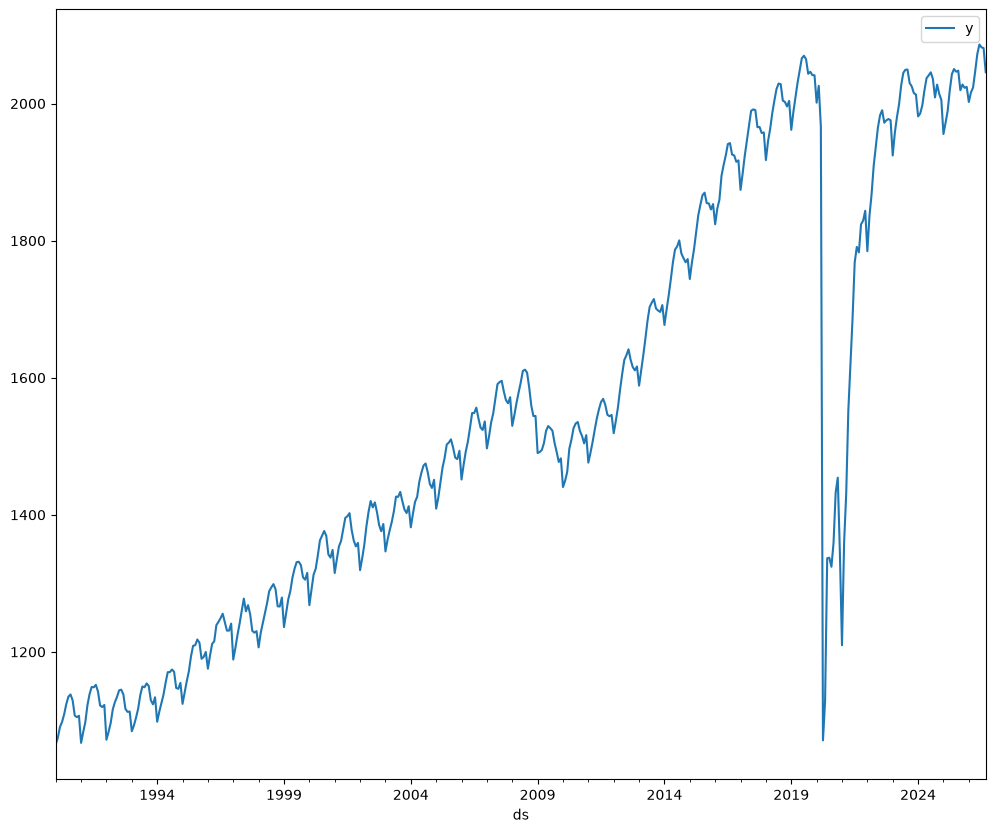

In [2]:
df.plot(x='ds', y='y', figsize=(12, 10));

## Paso 3: Entrenar y predecir (las 4 líneas de siempre)

In [3]:
m = Prophet()
m.fit(df)
future = m.make_future_dataframe(periods=12, freq='MS')
forecast = m.predict(future)

22:59:35 - cmdstanpy - INFO - Chain [1] start processing


22:59:35 - cmdstanpy - INFO - Chain [1] done processing


## Paso 4: Dibujar los puntos de cambio (lo nuevo de esta clase)

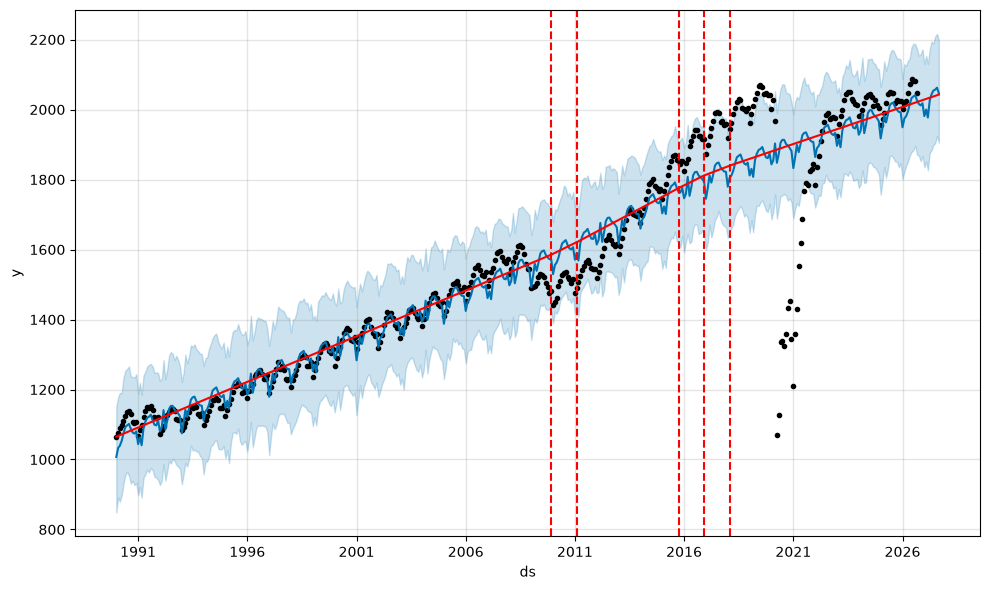

In [4]:
from prophet.plot import add_changepoints_to_plot   # en el video: from fbprophet.plot import ...

fig = m.plot(forecast)
a = add_changepoints_to_plot(fig.gca(), m, forecast)

## Paso 5 (extra): ¿En qué fechas exactas cambió la tendencia?

In [5]:
import numpy as np

cambios = pd.DataFrame({
    'fecha': m.changepoints.dt.date.values,
    'cambio_pendiente': m.params['delta'].mean(axis=0),
})
importantes = cambios[cambios['cambio_pendiente'].abs() >= 0.01].copy()   # el mismo umbral que usa el gráfico
importantes['tipo'] = np.where(importantes['cambio_pendiente'] > 0, 'acelera ↑', 'frena ↓')
importantes

,fecha,cambio_pendiente,tipo
16,2009-12-01,0.069779,acelera ↑
17,2011-02-01,0.047087,acelera ↑
21,2015-10-01,-0.043538,frena ↓
22,2016-12-01,-0.117472,frena ↓
23,2018-02-01,-0.050004,frena ↓


In [6]:
print('Puntos de cambio candidatos :', len(m.changepoints))
print('Puntos de cambio importantes:', len(importantes))
print('Último candidato posible    :', m.changepoints.max().date())

Puntos de cambio candidatos : 25
Puntos de cambio importantes: 5
Último candidato posible    : 2019-04-01


## Paso 6 (extra): Zoom a la crisis de 2008

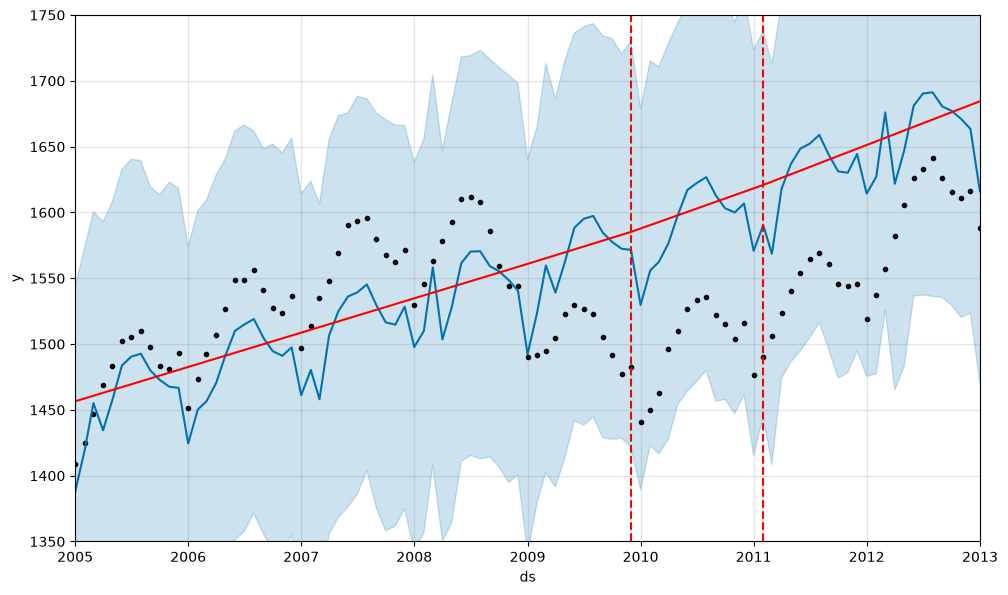

In [7]:
fig = m.plot(forecast)
a = add_changepoints_to_plot(fig.gca(), m, forecast)
plt.xlim(pd.Timestamp('2005-01-01'), pd.Timestamp('2013-01-01'))
plt.ylim(1350, 1750);

## Paso 7 (extra): Zoom al COVID (2018 – 2028)

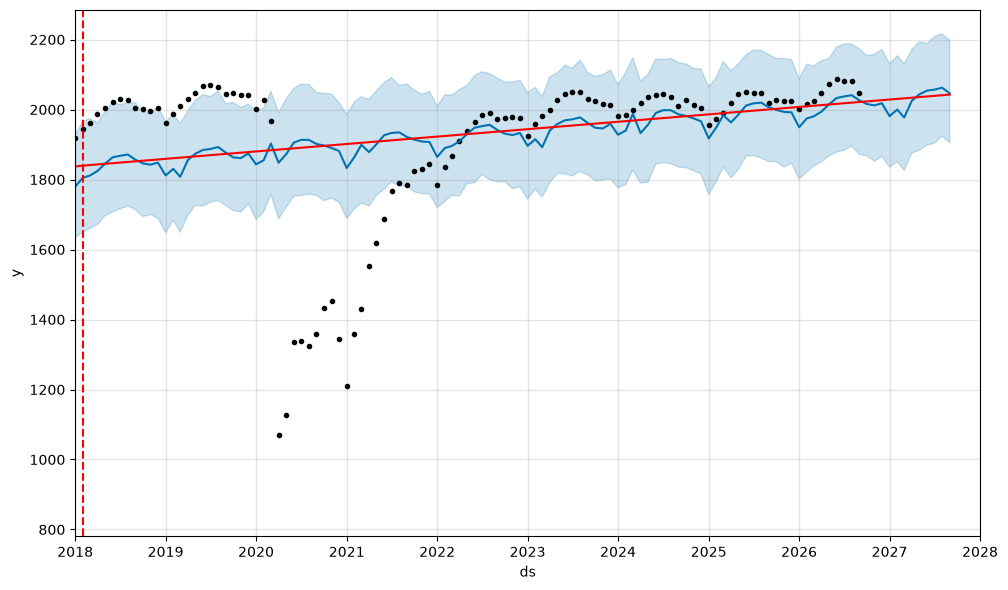

In [8]:
fig = m.plot(forecast)
a = add_changepoints_to_plot(fig.gca(), m, forecast)
plt.xlim(pd.Timestamp('2018-01-01'), pd.Timestamp('2028-01-01'));

## Paso 8 (extra): Quitar el COVID (como recomienda la documentación de Prophet)

Prophet permite marcar datos atípicos como **vacíos** (`None`). Así no los usa para aprender la tendencia.

22:59:36 - cmdstanpy - INFO - Chain [1] start processing


22:59:36 - cmdstanpy - INFO - Chain [1] done processing


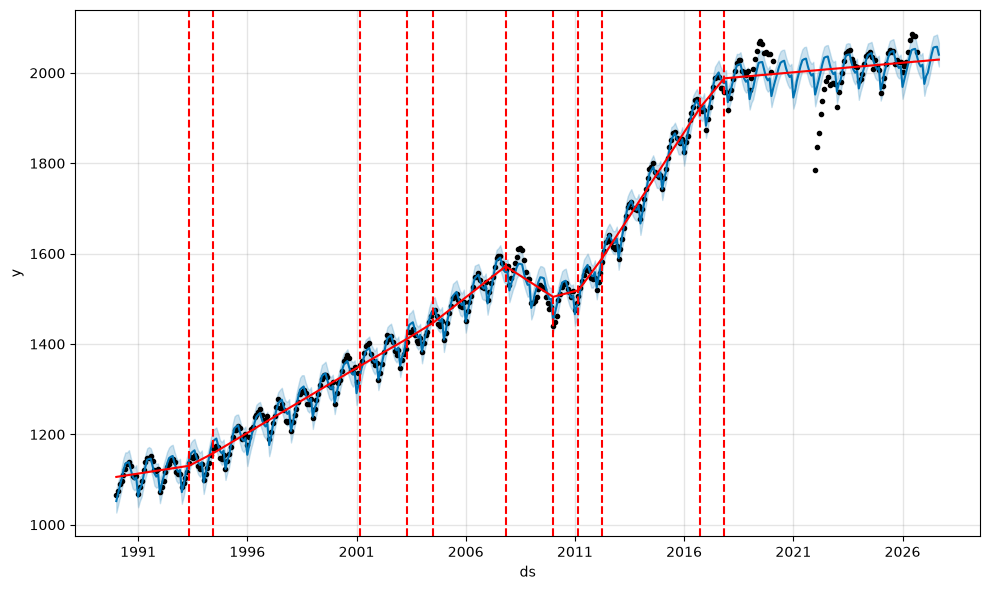

In [9]:
df_sin = df.copy()
covid = (df_sin['ds'] >= '2020-03-01') & (df_sin['ds'] <= '2021-12-01')
df_sin.loc[covid, 'y'] = None          # marzo 2020 -> diciembre 2021 quedan vacíos

m_sin = Prophet()
m_sin.fit(df_sin)
forecast_sin = m_sin.predict(m_sin.make_future_dataframe(periods=12, freq='MS'))

fig = m_sin.plot(forecast_sin)
a = add_changepoints_to_plot(fig.gca(), m_sin, forecast_sin)

In [10]:
cambios_sin = pd.DataFrame({
    'fecha': m_sin.changepoints.dt.date.values,
    'cambio_pendiente': m_sin.params['delta'].mean(axis=0),
})
importantes_sin = cambios_sin[cambios_sin['cambio_pendiente'].abs() >= 0.01].copy()
importantes_sin['tipo'] = np.where(importantes_sin['cambio_pendiente'] > 0, 'acelera ↑', 'frena ↓')
importantes_sin

,fecha,cambio_pendiente,tipo
2,1993-05-01,0.310659,acelera ↑
3,1994-06-01,0.065306,acelera ↑
9,2001-03-01,-0.011972,frena ↓
11,2003-05-01,0.037345,acelera ↑
12,2004-07-01,0.134783,acelera ↑
15,2007-11-01,-1.208216,frena ↓
17,2010-01-01,0.766410,acelera ↑
18,2011-03-01,0.931759,acelera ↑
19,2012-04-01,0.155134,acelera ↑
23,2016-10-01,-0.266289,frena ↓


In [11]:
print('Ancho promedio de la sombra CON COVID:', round((forecast['yhat_upper'] - forecast['yhat_lower']).mean(), 1))
print('Ancho promedio de la sombra SIN COVID:', round((forecast_sin['yhat_upper'] - forecast_sin['yhat_lower']).mean(), 1))

Ancho promedio de la sombra CON COVID: 299.6
Ancho promedio de la sombra SIN COVID: 50.7


## Resumen

```python
from prophet.plot import add_changepoints_to_plot
fig = m.plot(forecast)
a = add_changepoints_to_plot(fig.gca(), m, forecast)
```